# Imbalanced classification - approach overview

In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import os
import json
from modules.preprocessing import *
from pathlib import Path
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Problem description

Insurance company wants to offer a vehicle insurance to current health policyholders. We will fit the model in order to make the best prediction of the customer response "Yes" or "No". It will help the company determine which customers should they consider while making an offer.

# Dataset description

Data were downloaded from Kaggle website: 
https://www.kaggle.com/arashnic/imbalanced-data-practice

The dataset contains following variables:
- id: Customer ID; numerical
- Gender: Customer sex (Male/Female); categorical
- Age: Age of customer; numerical
- Driving_License: Indicator whether customer has driving license, 0 - "No", 1 - "Yes"; categorical
- Region_Code: Customer's region code; numerical
- Previously_Insured: Indicator if customer has ever been insured, 0 - "No", 1 - "Yes"; categorical
- Vehicle_Age: Age of vehicle divided into three classes, "<1 Year", "1-2 Years", ">2 Years"; categorical
- Vehicle_Damage: Indicator if vehicle has been damaged, 0 - "No", 1 - "Yes"; categorical
- Annual_Premium: Annual amount of money customer pays to insurance company; numerical
- Policy_Sales_Channel: Number of channel through which policy was sold to customer (broker, insurance agent etc.); numerical
- Vintage: Amount of days customer has been insured so far; numerical
- Response: Customer's response to vehicle insurance offer, 0 - "Yes", 1 - "No"; categorical


# Methodology

In this project, we will perform analysis basing on below steps:
1. Exploratory data analysis 
2. Choice of measure - we will choose the best measure related to our business problem.
3. Baseline algorithms - we will test several algorithms to obtain a starting point model performance. 
4. Model building, including:
    1. Applying imbalanced techniques
    2. Feature selection
    3. Hyperparameter optimization
    4. Prediction on the validation set
6. Evaluation on the test set and conclusions

# 1. Exploratory Data Analysis

### Initial exploration

Data read:

In [ ]:
data=pd.read_csv('./data/aug_train.csv')

Let's look how input data look in the dataframe:

In [8]:
data.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,167647,Male,22,1,7.0,1,< 1 Year,No,2630.0,152.0,16,0
1,17163,Male,42,1,28.0,0,1-2 Year,Yes,43327.0,26.0,135,0
2,32023,Female,66,1,33.0,0,1-2 Year,Yes,35841.0,124.0,253,0
3,87447,Female,22,1,33.0,0,< 1 Year,No,27645.0,152.0,69,0
4,501933,Male,28,1,46.0,1,< 1 Year,No,29023.0,152.0,211,0


In [9]:
data.shape

(382154, 12)

We will check the column types and if there are any missing values:

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 382154 entries, 0 to 382153
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    382154 non-null  int64  
 1   Gender                382154 non-null  object 
 2   Age                   382154 non-null  int64  
 3   Driving_License       382154 non-null  int64  
 4   Region_Code           382154 non-null  float64
 5   Previously_Insured    382154 non-null  int64  
 6   Vehicle_Age           382154 non-null  object 
 7   Vehicle_Damage        382154 non-null  object 
 8   Annual_Premium        382154 non-null  float64
 9   Policy_Sales_Channel  382154 non-null  float64
 10  Vintage               382154 non-null  int64  
 11  Response              382154 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 35.0+ MB


As can be seen from above output, there are no missing values in the dataset. However, we can notice "Driving_License", "Previously Insured" and "Response" columns are classified as integers due to they are already encoded. Let's change their type to object. Moreover, columns "Region_Code" and "Policy_Sales_Channel" should be classified as integers. 

In [24]:
# Removing ID column

data = data.drop('id', axis=1)

In [ ]:
data = prepare_data_types(data)
data.describe(include='all')

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,382154,382154.000000,382154.0,382154.000000,382154.0,382154,382154,382154.000000,382154.000000,382154.000000,382154.0
unique,2,NaN,2.0,NaN,2.0,2,2,NaN,NaN,NaN,2.0
top,Male,NaN,1.0,NaN,0.0,>1Year,No,NaN,NaN,NaN,0.0
freq,205603,NaN,381431.0,NaN,195211.0,215801,198501,NaN,NaN,NaN,319553.0
mean,NaN,38.545691,NaN,26.406868,NaN,NaN,NaN,30711.275391,111.939812,154.189429,NaN
std,NaN,15.226897,NaN,13.181240,NaN,NaN,NaN,17061.595703,54.286511,83.735107,NaN
min,NaN,20.000000,NaN,0.000000,NaN,NaN,NaN,2630.000000,1.000000,10.000000,NaN
25%,NaN,25.000000,NaN,15.000000,NaN,NaN,NaN,24546.000000,26.000000,81.000000,NaN
50%,NaN,36.000000,NaN,28.000000,NaN,NaN,NaN,31692.000000,145.000000,154.000000,NaN
75%,NaN,49.000000,NaN,35.000000,NaN,NaN,NaN,39447.750000,152.000000,227.000000,NaN


### Categorical features exploration

In [88]:
cat_features = data.select_dtypes('object').columns.tolist()
num_features = data.select_dtypes(['int32','float32']).columns.tolist()


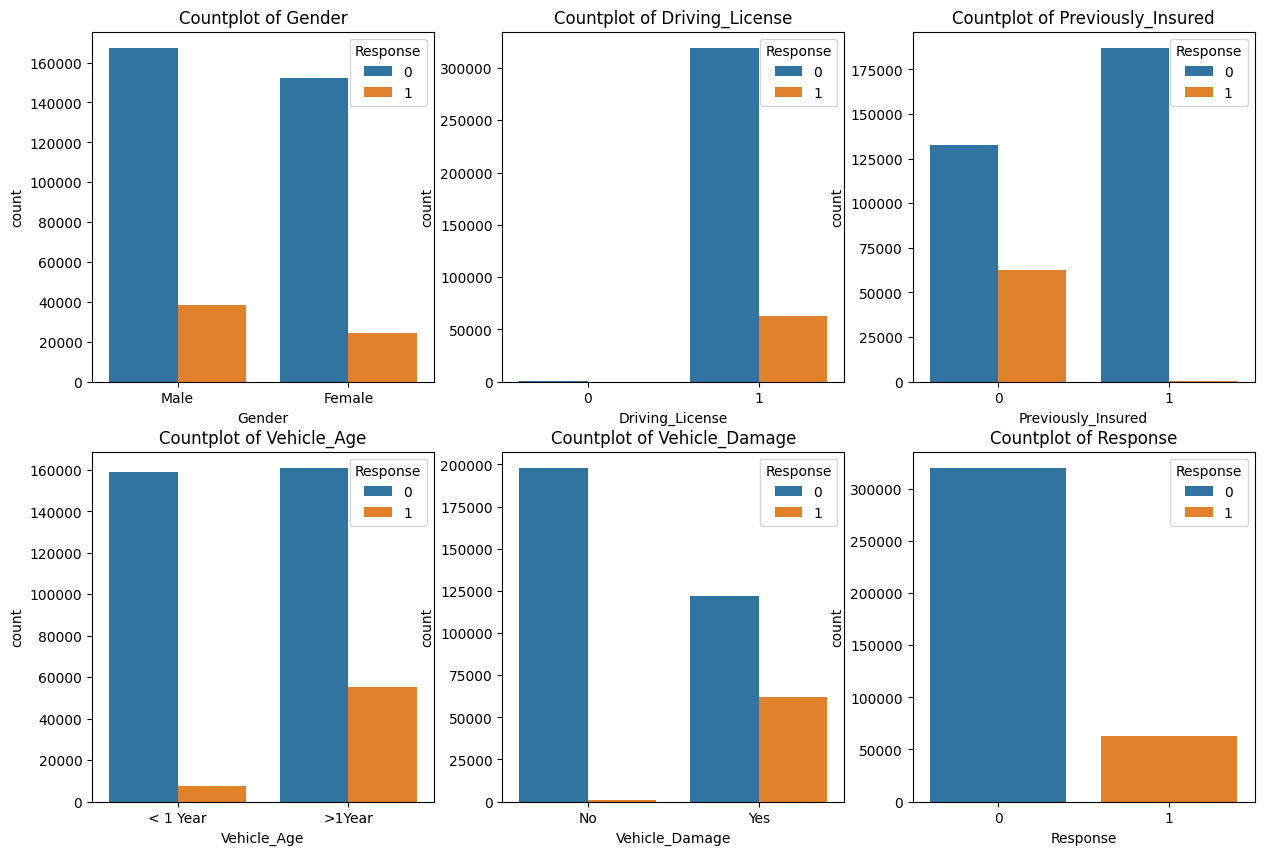

In [61]:
fig, axs = plt.subplots(2,3, figsize=(15,10))

for f, ax  in zip(cat_features,axs.ravel()):
    sns.countplot(data = data, x=f, ax = ax, hue="Response")
    ax.set_title(f'Countplot of {f}')
plt.show()

In [56]:
for f in cat_features:
    print(data[f].value_counts(normalize=True))

Gender
Male      0.538011
Female    0.461989
Name: proportion, dtype: float64
Driving_License
1    0.998108
0    0.001892
Name: proportion, dtype: float64
Previously_Insured
0    0.510818
1    0.489182
Name: proportion, dtype: float64
Vehicle_Age
1-2 Year     0.523810
< 1 Year     0.435304
> 2 Years    0.040887
Name: proportion, dtype: float64
Vehicle_Damage
No     0.519427
Yes    0.480573
Name: proportion, dtype: float64
Response
0    0.836189
1    0.163811
Name: proportion, dtype: float64


Clearly we see much more examples of Response variable is in class 0 (~84%) than class 1, which means the set is imbalanced. Also, the amount of customers without driving license in minimal, and it would be better to divide "Vehicle_Age" into 2 categories: less and above 1 year age.

In [58]:
data.loc[(data['Vehicle_Age']=="> 2 Years")|(data['Vehicle_Age']=="1-2 Year"),"Vehicle_Age"] = ">1Year"

### Numerical features exploration

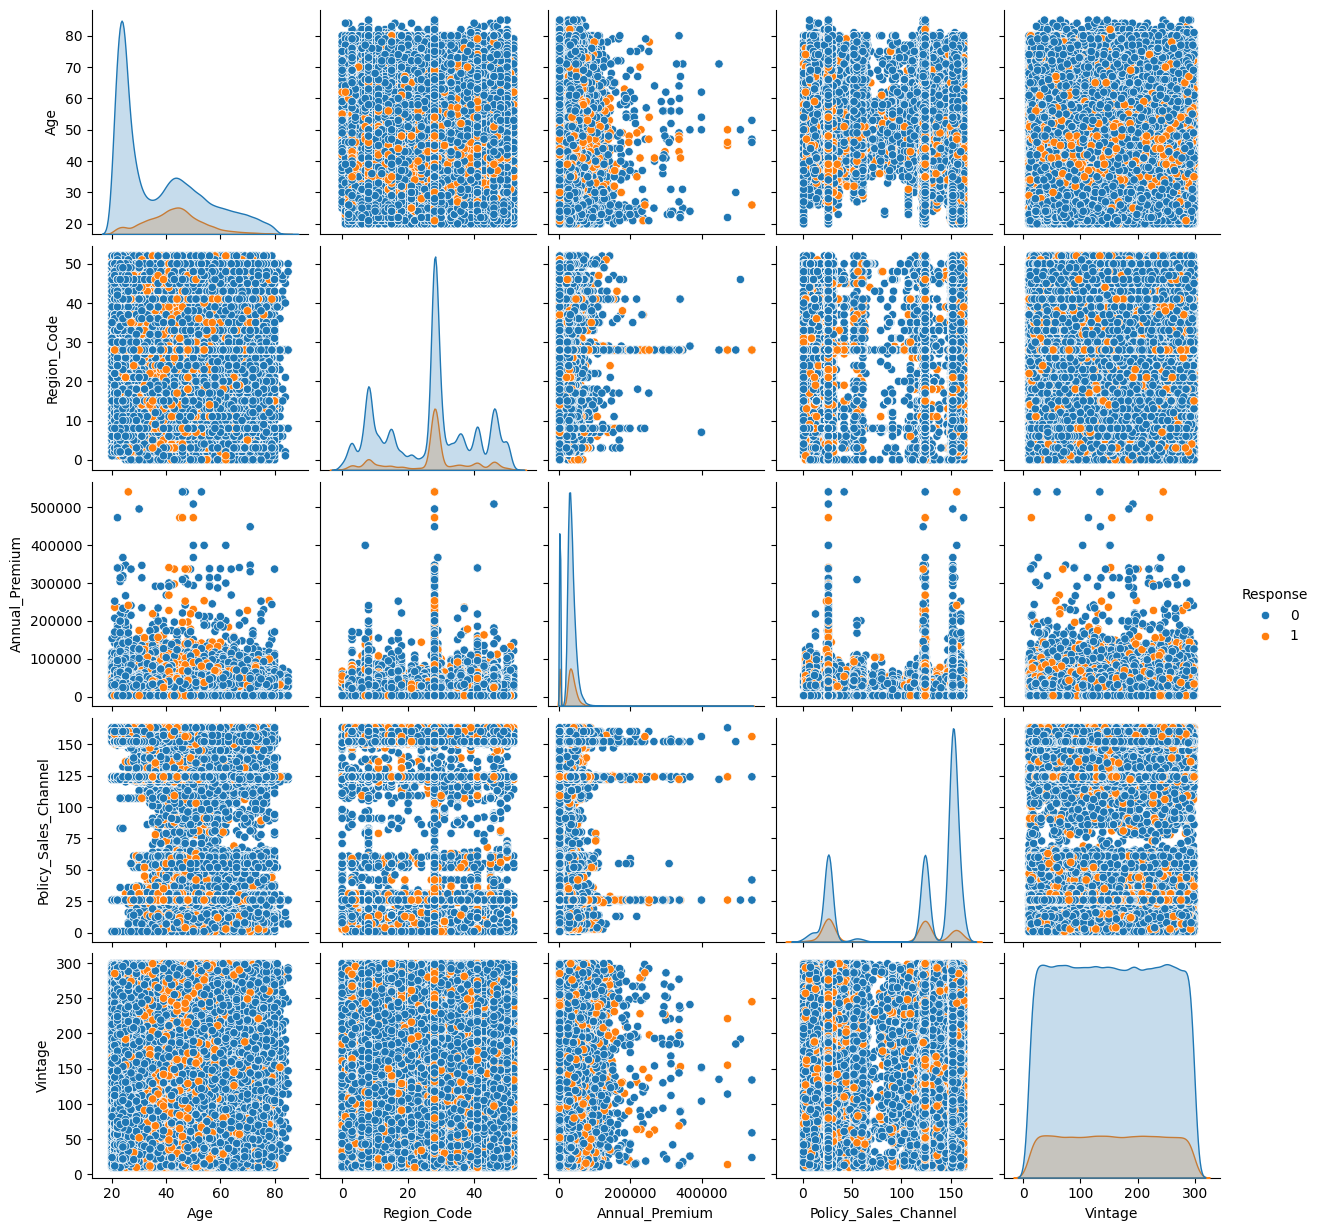

In [89]:
sns.pairplot(data[[*num_features,'Response']], hue='Response')
plt.show()

There are no visible relatinships between numerical variables.

Looking at numerical variables, their values vary from 0 to more than 500,000. Some scaling transformation will be needed in further data preparation.

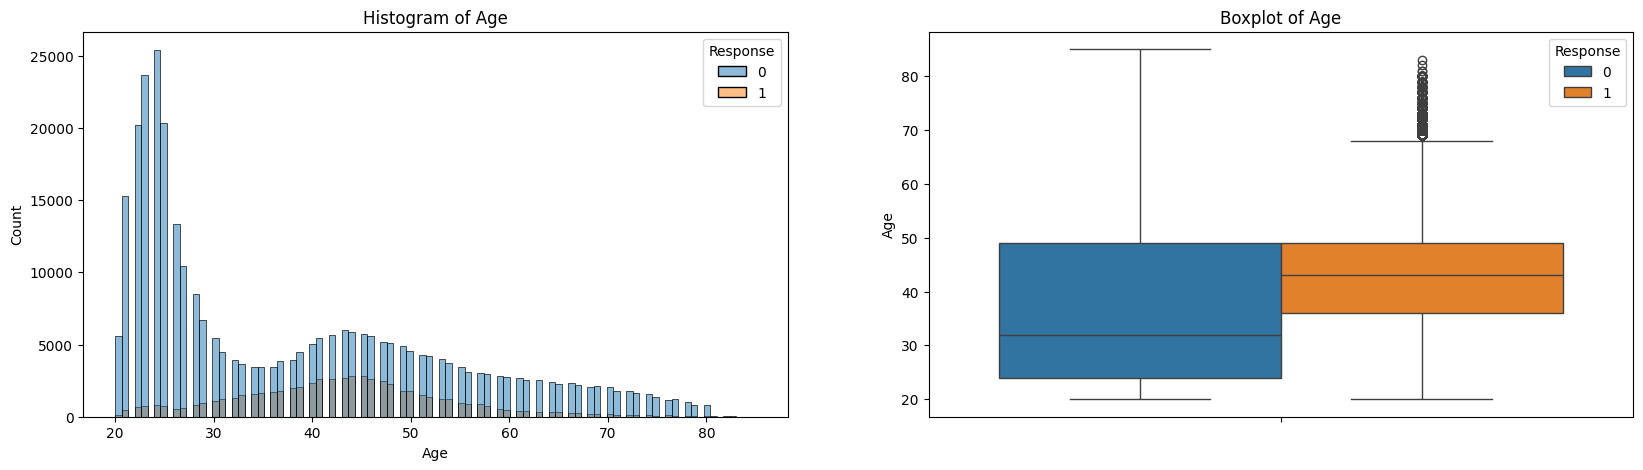

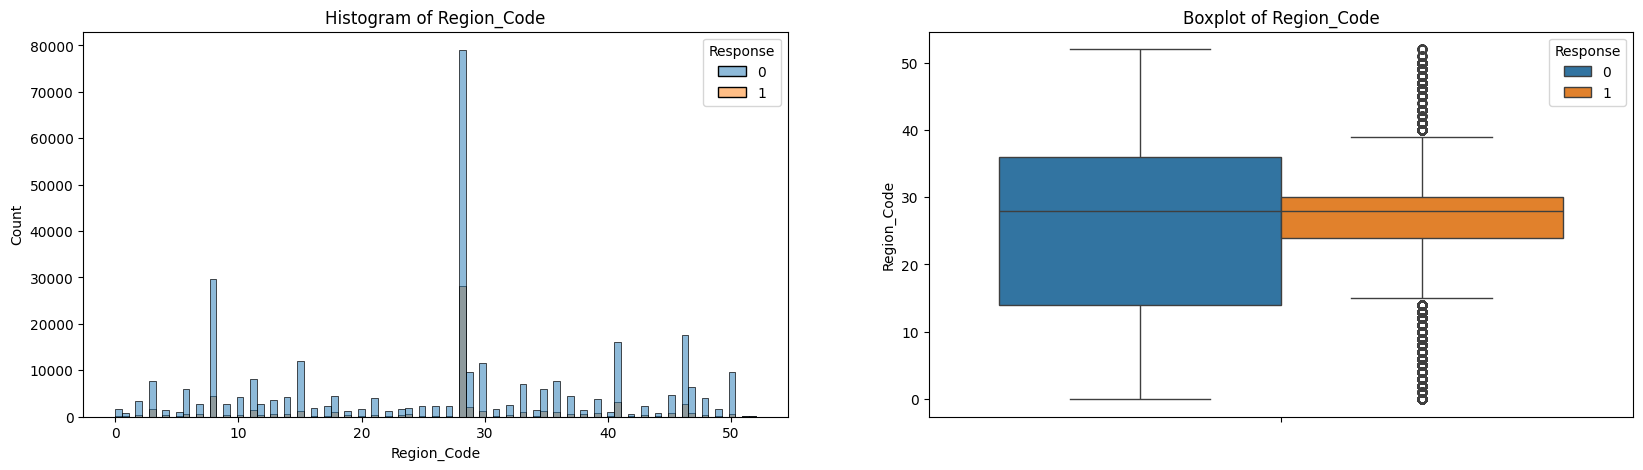

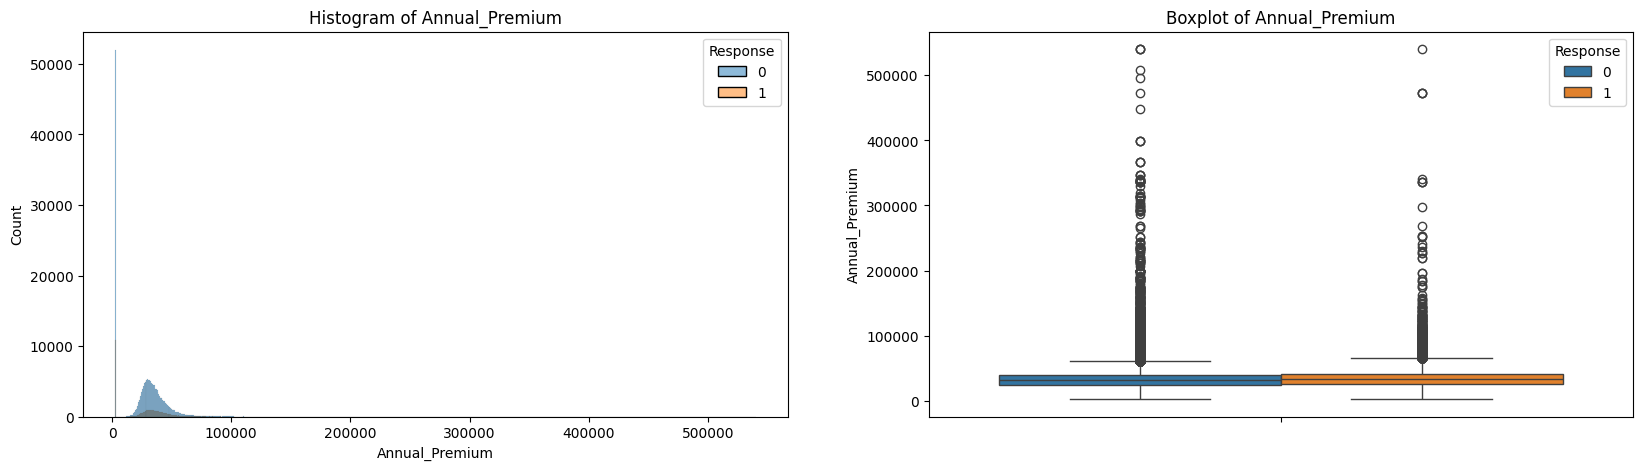

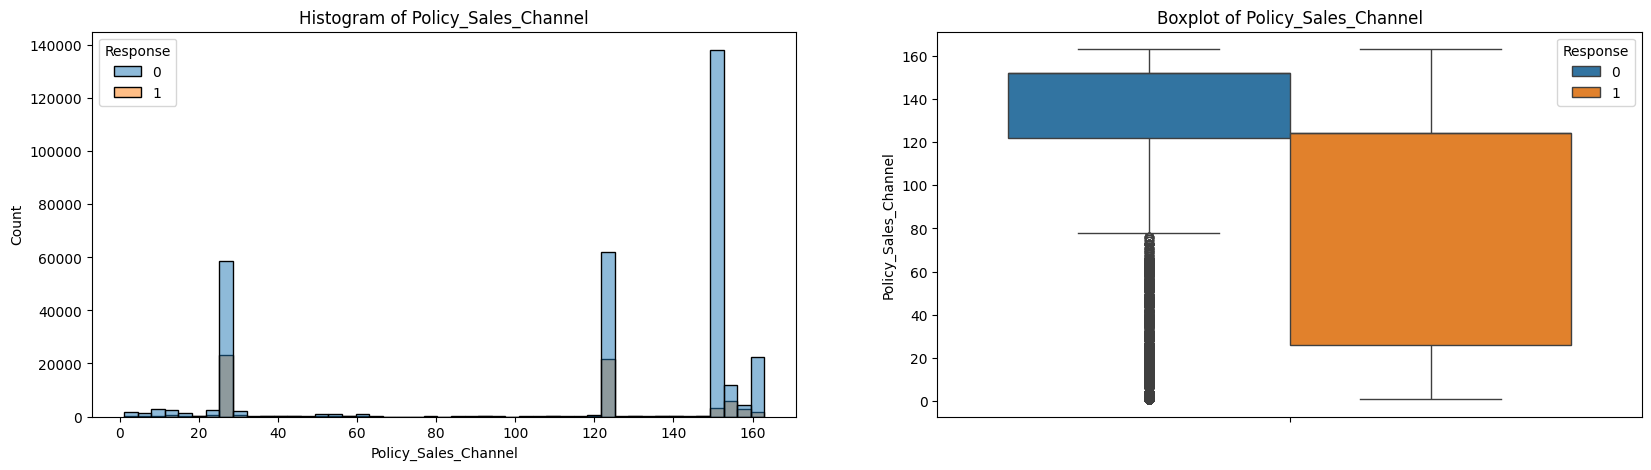

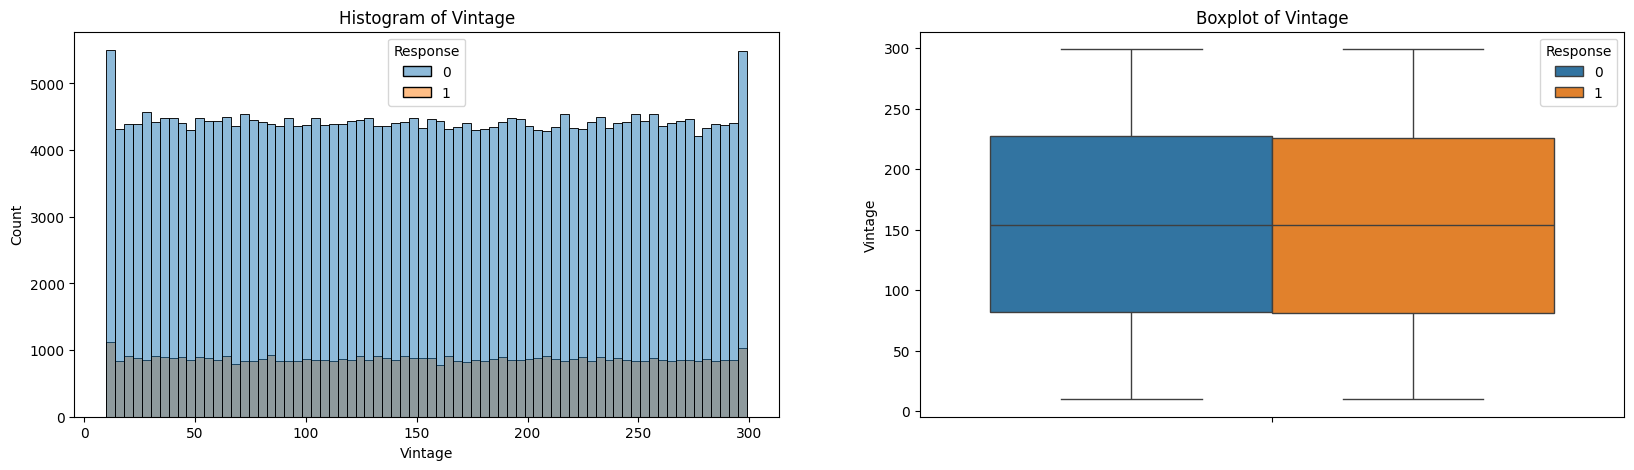

In [90]:
for col in num_features:

    fig, axs = plt.subplots(1,2, figsize=(20,5))
    axs[0].set_title(f'Histogram of {col}')
    sns.histplot(data=data, x=col, ax = axs[0], hue='Response')
    axs[1].set_title(f'Boxplot of {col}')
    sns.boxplot(data=data, y=col, ax = axs[1], hue='Response')
    plt.show()

In [92]:
for col in num_features:
    print(f'{col} skeweness: ', data[col].skew())

Age skeweness:  0.6968803705160445
Region_Code skeweness:  -0.11700322
Annual_Premium skeweness:  1.7204514
Policy_Sales_Channel skeweness:  -0.8934558634125944
Vintage skeweness:  0.004005294203146983


In [93]:
for col in num_features:
    print(f'{col} skeweness - negative response: ', data.loc[data["Response"]==0,col].skew())
    print(f'{col} skeweness- positive response: ', data.loc[data["Response"]==1,col].skew())

Age skeweness - negative response:  0.8111159976897763
Age skeweness- positive response:  0.34826691605088106
Region_Code skeweness - negative response:  -0.08856452
Region_Code skeweness- positive response:  -0.3163224
Annual_Premium skeweness - negative response:  1.6904393
Annual_Premium skeweness- positive response:  1.8200506
Policy_Sales_Channel skeweness - negative response:  -1.071148478844744
Policy_Sales_Channel skeweness- positive response:  -0.18450160005896502
Vintage skeweness - negative response:  0.004075596842066518
Vintage skeweness- positive response:  0.003632632168838369


### Correlations

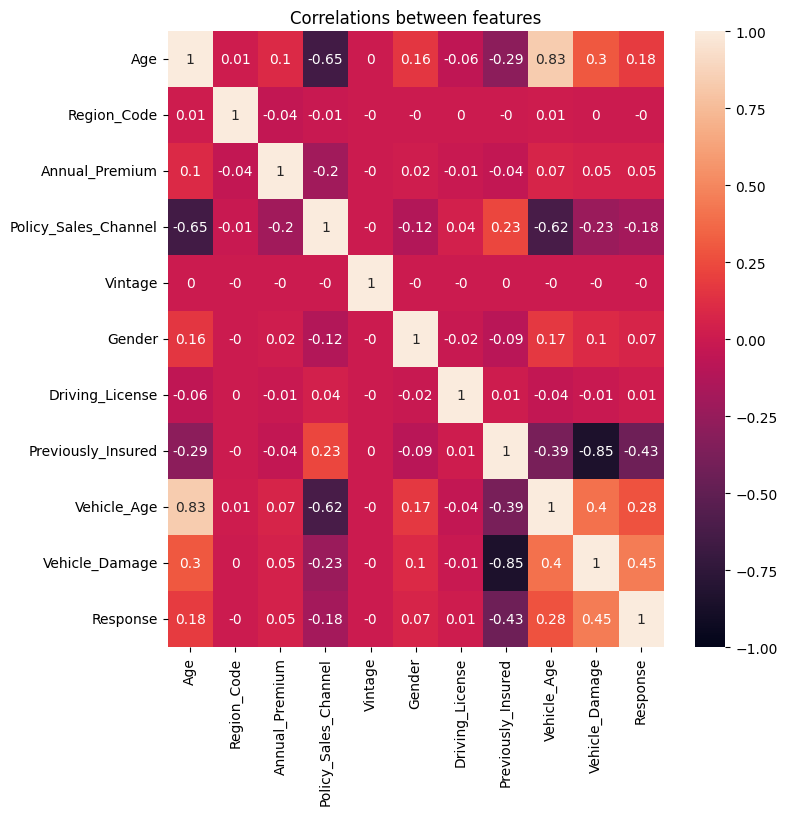

In [128]:
plot_corr(data)

### Conclusions

*   The largest Age group consist of customers aged between 20 and 30, but the largest group on customers preferring car insurance is between 40-50 years
*   The largest Region Code group consist of customers with code close to 30.
*   The most popular policy channels have numbers around 150-160. 
*   Vintage and Annual_Premium variables have similar distriutions in both customer groups, with majority of customers paying rather small amounts.
*   There are some outliers visible on the boxplots, however those come from skewed distributions - Age and Annual_Premium are right-skewed, while Policy_Sales_Channel is left-skewed. Vintage has symmetric distribution.
*   The strongest correlations are between:
    *   Age-Vehicle_Age
    *   Vehicle_Damage-Previously_Insured
    *   Policy_Sales_Channel-Age/Vehicle_Age
*   Semi-strong correlations are between:
    *   Response-Vehicle_Damage/Previously_Insured



# 2. Choice of Metrics

The aim is to predict customers response (Yes or No) to vehicle insurane offer. From business perspective, it is crucial for insurance company to properly choose customers.  From the given dataset we can see majority of customers do not decide to buy insurance. The choice of the best metric would in every case depend on particular company's preferences and insights. For this task, it will be assumed that missing relevant customer will be more impactful, therefore recall score will be used.

# 3. Preprocessing and baseline prediction

Several algorithms with default parameters will be tested to set the baseline prediction level. 
We will consider following algorithms:
- Naive prediction (Dummy Classifier)
- CatBoost
- LightGBM
- MLP

In order to maintain the same 0-1 class balance, Stratified K-Fold with 5 splits will be used as cross-validator. 
Recall will be used as scoring function.

Preprocessing will include:
*   Encoding categorical features (for Dummy Classifier)
*   Scaling features (for MLP)

### Train - test split

In [9]:
training, test = train_test_split(data, test_size=0.2, stratify=data["Response"])

In [ ]:
training.to_csv('./data/train.csv', index=False)
test.to_csv('./data/test.csv', index=False)

### Dummy prediction on validation set

Validation set will be derived from train set before training phase.

In [13]:
# Baseline - Dummy model
dummy_results = baseline()
dummy_results

0.16206070287539937

Recall score for DummyClassifier is very low due to high imbalance.

### Baseline prediction on validation set

In [ ]:
config = {
    'method':None
}

In [ ]:
with open('./config.json','w') as f:
    json.dump(config, f)

In [ ]:
%run scripts/train.py

Training CatBoost
Learning rate set to 0.121318
0:	learn: 0.4952393	test: 0.4957452	best: 0.4957452 (0)	total: 279ms	remaining: 4m 38s
Stopped by overfitting detector  (10 iterations wait)

bestTest = 0.2746291178
bestIteration = 219

Shrink model to first 220 iterations.
Training LightGBM
[LightGBM] [Info] Number of positive: 37561, number of negative: 191731
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002926 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 766
[LightGBM] [Info] Number of data points in the train set: 229292, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.163813 -> initscore=-1.630127
[LightGBM] [Info] Start training from score -1.630127
Training MLP


100%|██████████| 10/10 [02:16<00:00, 13.67s/it]


,CatBoost,LightGBM,MLP
Recall,0.373722,0.398562,0.437061


Recall scores on the validation set are similar for all non-dummy models, with the highest score achieved by MLP.

### Optimization

In this section, full optimization will be applied for each method:

    1. Feature selection
    2. Hyperparameter optimization
    3. Evaluation on the validation set

In [2]:
config['method'] = 'sampling'
config['trials'] = 5

with open('./config.json','w') as f:
    json.dump(config, f)

In [ ]:
%run scripts/train.py

Optimizing CatBoost with method sampling


[I 2026-11-09 08:13:24,643] A new study created in memory with name: no-name-89bd9d4f-f5b4-4212-bf1a-05211e3d5570


  0%|          | 0/5 [00:00<?, ?it/s]

[CV] END .................................................... total time=  51.4s
[CV] END .................................................... total time=  51.5s
[CV] END .................................................... total time=  49.7s
[CV] END .................................................... total time=  50.4s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  4.2min finished


[CV] END .................................................... total time=  50.9s
[I 2026-11-09 08:17:39,072] Trial 0 finished with value: 0.8293442909818933 and parameters: {'0': False, '1': False, '2': False, '3': False, '4': False, '5': False, '6': True, '7': True, '8': True, '9': False, 'sampling_strategy': 0.9486784447133122, 'iterations': 946, 'learning_rate': 0.24511778839495565, 'depth': 6, 'min_data_in_leaf': 92, 'l2_leaf_reg': 4.114854813905815, 'random_strength': 1.6859660963216152, 'loss_function': 'Logloss', 'random_seed': 42, 'verbose': False}. Best is trial 0 with value: 0.8293442909818933.
[CV] END .................................................... total time=  39.3s
[CV] END .................................................... total time=  40.5s
[CV] END .................................................... total time=  41.0s
[CV] END .................................................... total time=  40.6s


... (31 outputs left out)

 30%|██▉       | 11/37 [01:46<04:12,  9.69s/it]


[I 2026-11-09 09:01:52,034] Trial 4 finished with value: 0.9666932821273804 and parameters: {'0': False, '1': True, '2': True, '3': True, '4': True, '5': False, '6': True, '7': False, '8': False, '9': True, 'sampling_strategy': 0.47321059285353295, 'n_layers': 2, 'hidden_size': 32, 'dropout': 0.06296397708680157, 'epochs': 37, 'batch_size': 64, 'learning_rate': 2.3361232298094482e-05, 'patience': 8}. Best is trial 3 with value: 0.9982427954673767.
Training MLP


 16%|█▌        | 4/25 [00:44<03:51, 11.04s/it]


,CatBoost,LightGBM,MLP
Recall,0.870128,0.896486,0.998243


In [ ]:
config['method'] = 'weights'
config['trials'] = 5
with open('./config.json','w') as f:
    json.dump(config, f)

In [ ]:
%run scripts/train.py

Optimizing CatBoost with method weights


[I 2026-11-09 10:53:13,565] A new study created in memory with name: no-name-7cdbd74c-247a-4e82-9e4a-63bc6297f794


  0%|          | 0/5 [00:00<?, ?it/s]

[CV] END .................................................... total time=  53.6s
[CV] END .................................................... total time=  48.7s
[CV] END .................................................... total time=  48.4s
[CV] END .................................................... total time=  54.7s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  4.3min finished


[CV] END .................................................... total time=  51.8s
[I 2026-11-09 10:57:31,368] Trial 0 finished with value: 0.9648836833336949 and parameters: {'0': False, '1': True, '2': True, '3': False, '4': True, '5': True, '6': True, '7': False, '8': False, '9': True, 'iterations': 899, 'learning_rate': 0.09722854056403755, 'depth': 10, 'scale_pos_weight': 12, 'min_data_in_leaf': 84, 'l2_leaf_reg': 7.629383526847534, 'random_strength': 1.006153305155398, 'loss_function': 'Logloss', 'random_seed': 42, 'verbose': False}. Best is trial 0 with value: 0.9648836833336949.
[CV] END .................................................... total time=  14.2s
[CV] END .................................................... total time=  13.0s
[CV] END .................................................... total time=  14.8s
[CV] END .................................................... total time=  15.7s


... (31 outputs left out)

 25%|██▌       | 3/12 [01:04<03:14, 21.57s/it]


[I 2026-11-09 11:24:51,557] Trial 4 finished with value: 0.8726038336753845 and parameters: {'0': True, '1': False, '2': True, '3': False, '4': True, '5': True, '6': True, '7': True, '8': False, '9': False, 'n_layers': 4, 'hidden_size': 128, 'dropout': 0.08682098927597431, 'epochs': 12, 'batch_size': 64, 'learning_rate': 0.002181360255910813, 'patience': 3, 'positive_class_weight': 3}. Best is trial 0 with value: 1.0.
Training MLP


 63%|██████▎   | 12/19 [00:57<00:33,  4.78s/it]


,CatBoost,LightGBM,MLP
Recall,0.967572,0.996885,1.0


In [3]:
config['method'] = 'prob'
config['trials'] = 5

with open('./config.json','w') as f:
    json.dump(config, f)

In [ ]:
%run scripts/train.py

Optimizing CatBoost with method prob


[I 2026-11-09 13:09:00,359] A new study created in memory with name: no-name-113e796c-1b8d-4853-b464-1197db29d583


  0%|          | 0/5 [00:00<?, ?it/s]

Cross-validation progress: 100%|██████████| 5/5 [02:52<00:00, 34.58s/it]


[I 2026-11-09 13:11:53,300] Trial 0 finished with value: 0.8717551380943249 and parameters: {'0': False, '1': True, '2': True, '3': False, '4': True, '5': True, '6': False, '7': False, '8': False, '9': True, 'iterations': 852, 'learning_rate': 0.08782082493304173, 'depth': 8, 'scale_pos_weight': 4, 'min_data_in_leaf': 84, 'l2_leaf_reg': 12.153830780302101, 'random_strength': 1.4264457638835362, 'loss_function': 'Logloss', 'random_seed': 42, 'verbose': False, 'threshold': 0.5416342007828069}. Best is trial 0 with value: 0.8717551380943249.


Cross-validation progress: 100%|██████████| 5/5 [02:23<00:00, 28.61s/it]


... (29 outputs left out)

100%|██████████| 34/34 [03:50<00:00,  6.78s/it]


[I 2026-11-09 13:47:51,140] Trial 4 finished with value: 0.0 and parameters: {'0': True, '1': False, '2': True, '3': True, '4': False, '5': True, '6': False, '7': True, '8': False, '9': False, 'n_layers': 4, 'hidden_size': 32, 'dropout': 0.11349043144703352, 'epochs': 34, 'batch_size': 128, 'learning_rate': 0.0005587500804260794, 'patience': 10, 'threshold': 0.7992746422403947}. Best is trial 0 with value: 0.0010383386397734284.
Training MLP


100%|██████████| 29/29 [06:25<00:00, 13.30s/it]


,CatBoost,LightGBM,MLP
Recall,0.872125,0.916134,0.00016


#### Optimization conclusions

*   It is visible that applying techniques related to imbalanced datasets strongly improves metrics for all models
*   For method with SMOTE-NC, all models achieved validation scores higher than 0.87, with MLP being close to perfect score
*   For method involving weights modification, all models achieved validation scores higher than 0.96, with MLP producing perfect prediction
*   For method involving probability threshold calibration, results are more diversified, with LightGBM achieving the best result (above 0.91), CatBoost performing also quite well (above 0.87), but with MLP producing completely incorrect prediction

### Inference on the test set

Saved models obtained during optimization for each method will be now evaluated on unseen test data.

In [ ]:
# Baseline models - test set results 

%run scripts/inference.py

--- Running inference for: MLP (method: baseline) ---


,Model,Method,Threshold,Recall_Score
0,MLP,baseline,0.5,0.443131


In [ ]:
# Optimized models - test set results - method - SMOTE-NC

%run scripts/inference.py

--- Running inference for: MLP (method: sampling) ---


,Model,Method,Threshold,Recall_Score
0,MLP,sampling,0.5,0.997843


In [ ]:
# Optimized models - test set results - method - weights calibration

%run scripts/inference.py

--- Running inference for: MLP (method: weights) ---


,Model,Method,Threshold,Recall_Score
0,MLP,weights,0.5,1.0


In [ ]:
# Optimized models - test set results - method - probability threshold

%run scripts/inference.py

--- Running inference for: LightGBM (method: prob) ---


,Model,Method,Threshold,Recall_Score
0,LightGBM,prob,0.695488,0.910942


# Conclusions

In [27]:
for method in ['sampling', 'weights', 'prob']:
    path = os.path.join('./artifacts', method, f'config_inference_{method}.json')
    with open(path, 'r') as f:
        config = json.load(f)
    print(f'Features selected during method: {method}')
    print(data.iloc[:,:-1].iloc[:,config["features"]].columns.tolist(),'\n')

Features selected during method: sampling
['Gender', 'Age', 'Region_Code', 'Previously_Insured', 'Annual_Premium'] 

Features selected during method: weights
['Vehicle_Damage', 'Annual_Premium', 'Vintage'] 

Features selected during method: prob
['Gender', 'Age', 'Previously_Insured'] 



*   After applying imbalanced techniques, recall score on the validation set improved strongly for MLP (resampling and weights techniques) and boosting models (all techniques)
*   Technique with the best result is weights calibration, combined with MLP model, applied on 'Vehicle_Damage', 'Annual_Premium' and 'Vintage' features. Score on the test set is also very good
*   Features selected for all techniques are reasonable  - especially for the best model, the highest business value is associated with whether the vehicle has been previously damaged, how long the custoemr is insured and how high is the paid premium 
*   There is still room for improving the models, e.g. by combining some of the techniques, applying more trials during optimization, or testing other MLP architectures.